# CSC14120 — LẬP TRÌNH SONG SONG: BÁO CÁO GIỮA KỲ (MIDTERM REPORT)
## Đồ án: Ghép ảnh Panorama tăng tốc bằng CUDA (CUDA-Accelerated Panorama Image Stitching)
> **Cột mốc:** Nộp bài giữa kỳ (Quality Gate B — Tuân thủ Kế hoạch dự án Plan v4)  
> **Nhóm thực hiện:** Nhóm 19 (Group 19)  
> **Hợp đồng thực thi:** Google Colab mới tinh hoặc CPU cục bộ, C++17; kết quả lưu bên dưới được đo đạc thực tế từ CPU host tại Cell 2.2.  
> **Kho lưu trữ mã nguồn:** [GitHub Repository (thong7d/Panorama-Stitching)](https://github.com/thong7d/Panorama-Stitching)  
> **Thư mục dữ liệu:** [Google Drive Dataset Folder](https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link)  

---

### THÀNH VIÊN NHÓM VÀ PHÂN CHIA CÔNG VIỆC (TEAM MEMBERS AND WORKLOAD ALLOCATION)

| STT | Họ và tên | MSSV | Vai trò và nhiệm vụ cụ thể |
|:---:|---|:---:|---|
| 1 | **Phạm Minh Thông** (Nhóm trưởng) | 23120364 | Kiến trúc tổng thể, Quy trình tiền xử lý 16:9, Giai đoạn 1 (Lọc Gaussian) & Giai đoạn 5 (Hartley RANSAC DLT) |
| 2 | **Nguyễn Lê Tấn Tiến** | 23120369 | Thu thập tập ảnh đa địa điểm & Manifest, Giai đoạn 2 (FAST-9 NMS Top-K) & Giai đoạn 3 (Mô tả ORB) |
| 3 | **Đào Quốc Tuấn** | 23120392 | Giai đoạn 4 (Khớp Hamming 8x32-bit), Giai đoạn 6 (Chiếu ngược Bilinear), Bộ kiểm thử Benchmark & Phân tích Amdahl |

### KẾ HOẠCH PHÂN CÔNG CÔNG VIỆC ĐẾN CUỐI KỲ (WORK ALLOCATION THROUGH THE FINAL MILESTONE)

| Phiên bản / Sản phẩm bàn giao | Phạm Minh Thông | Nguyễn Lê Tấn Tiến | Đào Quốc Tuấn |
|---|---|---|---|
| **V0 (Tuần tự C++)** | Kiến trúc, S1, S5, Tích hợp hệ thống | Dataset, S2, S3 | S4, S6, Đo đạc & Phân tích Amdahl |
| **V1 (CUDA cơ bản)** | Hợp đồng bộ nhớ, Kernel S1 & S5 | Kernel S2 & S3 | Kernel S4 & S6, Thu thập số liệu |
| **V2 (Tối ưu hóa 1)** | Tích hợp & Profile ứng viên Shared Memory | Xác thực tính tương đương detector/descriptor | Đo đạc benchmark và kiểm tra truyền dữ liệu |
| **V3 (Tối ưu hóa 2)** | Quality gate độ chính xác & Tích hợp bản phát hành | Ứng viên thu gọn compaction / Constant memory | Ứng viên so khớp/warp & So sánh Nsight Compute |
| **Báo cáo cuối kỳ & Demo** | Trưởng nhóm kỹ thuật, Tính nhất quán báo cáo | Bộ sưu tập dataset và phân tích phương pháp | Toàn bộ benchmark, biểu đồ, video demo |

*Ghi chú:* Tên của V2/V3 được giữ tạm thời cho đến khi có dữ liệu profiling thực tế của V1, nhưng trách nhiệm phân công và xác thực của từng thành viên là cố định. Mọi thành viên đều nắm vững toàn bộ 6 giai đoạn để tham gia vấn đáp cuối kỳ.


---
## 1. HIỂU BÀI TOÁN & KIẾN TRÚC QUY TRÌNH (PROBLEM UNDERSTANDING & PIPELINE ARCHITECTURE)

### 1.1 Mục tiêu (Objective)
Mục tiêu của bài toán là ghép hai ảnh tĩnh có vùng chồng lấn (chụp từ một tâm phối cảnh duy nhất bằng cách xoay camera tại chỗ, độ chồng lấn 30%–50%) thành một ảnh toàn cảnh (Panorama) góc rộng, độ phân giải cao và liền mạch trong hệ tọa độ của ảnh bên trái (Ảnh A).

### 1.2 Quy trình 6 giai đoạn & Luồng dữ liệu (Six-Stage Pipeline & Data-Flow Architecture)

```text
[Ảnh đầu vào A (RGB)]                       [Ảnh đầu vào B (RGB)]
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Giai đoạn 1:      │                       │ Giai đoạn 1:      │
│ Tiền xử lý        │ ──> Mức xám Float ───>│ Tiền xử lý        │
│ (Y=0.299R+0.587G) │     (Gaussian 5x5)    │ (Y=0.299R+0.587G) │
└───────────────────┘                       └───────────────────┘
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Giai đoạn 2:      │                       │ Giai đoạn 2:      │
│ Phát hiện đặc trưng│ ──> Top-K Keypoints ─>│ Phát hiện đặc trưng│
│ (FAST-9 + Top-K)  │     (x, y, angle, resp│ (FAST-9 + Top-K)  │
└───────────────────┘                       └───────────────────┘
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Giai đoạn 3:      │                       │ Giai đoạn 3:      │
│ Trích xuất mô tả  │ ──> 256-bit Descr ───>│ Trích xuất mô tả  │
│ (Oriented BRIEF)  │     (8 x uint32_t)    │ (Oriented BRIEF)  │
└───────────────────┘                       └───────────────────┘
         │                                           │
         └───────────────────┬───────────────────────┘
                             ▼
                  ┌─────────────────────┐
                  │ Giai đoạn 4:        │
                  │ Khớp đặc trưng      │
                  │ (Hamming + Lowe)    │
                  └─────────────────────┘
                             │
                             ▼ Các cặp điểm tương đồng (Matches)
                  ┌─────────────────────┐
                  │ Giai đoạn 5:        │
                  │ Ước lượng Homography│
                  │ (RANSAC + Norm DLT) │
                  └─────────────────────┘
                             │
                             ▼ Ma trận tối ưu H_A_to_B (3x3)
                  ┌─────────────────────┐
                  │ Giai đoạn 6:        │ <─── [Ảnh gốc RGB A & B]
                  │ Chiếu hình & Trộn   │
                  │ (Bilinear + Feather)│
                  └─────────────────────┘
                             │
                             ▼
                 [Ảnh toàn cảnh Panorama]
```

### 1.3 Tham số bất biến & Hợp đồng chất lượng (Invariant Parameters & Quality Contracts)
Theo **Kế hoạch dự án Plan v4 Mục 3**, các tham số và quy ước toán học sau đây được khóa cố định trên mọi phiên bản (từ V0 CPU tuần tự cho tới V1, V2, V3 CUDA GPU) để đảm bảo so sánh tăng tốc công bằng và có giá trị học thuật:

| Giai đoạn | Thuật toán / Phương pháp | Hợp đồng bất biến & Tham số khóa |
|---|---|---|
| **Giai đoạn 1** | Tiền xử lý (Preprocessing) | Mức xám chuẩn $Y = 0.299R + 0.587G + 0.114B$; Lọc nhiễu Gaussian 5×5 ($\sigma=1.0$), giới hạn biên boundary clamping. |
| **Giai đoạn 2** | FAST-9 + NMS + Top-K | Ngưỡng góc FAST-9 $T=20$ trên đường tròn Bresenham 16 điểm; Non-Maximum Suppression 3×3; Tối đa $K=1000$ keypoints; Sắp xếp tất định: `(response GIẢM DẦN, linear_index TĂNG DẦN)`. |
| **Giai đoạn 3** | Oriented BRIEF / ORB | Kích thước patch $31\times 31$, góc định hướng từ Trọng tâm cường độ (Intensity Centroid) $[-\pi, \pi]$; Bảng 256 cặp kiểm tra chuẩn từ OpenCV `bit_pattern_31_`; Loại bỏ biên an toàn ($R < 20$ px). |
| **Giai đoạn 4** | So khớp vét cạn Hamming | Descriptor 256-bit lưu dưới dạng 8 từ $\times$ 32-bit (`uint32_t words[8]`), tính khoảng cách bit bằng popcount; Kiểm định tỷ số Lowe (Lowe's Ratio Test): $\text{dist}_1 < 0.75 \times \text{dist}_2$. |
| **Giai đoạn 5** | RANSAC Homography | 2000 lượt giả thuyết (hypotheses); DLT 4 điểm chuẩn hóa đẳng hướng Hartley; Khử Gauss từng phần (partial pivoting); Ngưỡng sai số chiếu lại $3.0$ px; Bộ sinh số ngẫu nhiên tất định LCG seed 42. |
| **Giai đoạn 6** | Chiếu ngược & Trộn mềm | Ánh xạ tọa độ ngược qua $H_{A\to B}$; Lấy mẫu nội suy song tuyến (Bilinear sampling); Trọng số làm mượt đối xứng (Symmetric feathering) theo khoảng cách tới cả 4 biên để triệt tiêu vết nối. |

### 1.4 Biện luận chất lượng cho các phương pháp đã chọn (Quality Rationale)

| Giai đoạn | Lý do lựa chọn thuật toán đảm bảo chất lượng đầu ra |
|---|---|
| **S1** | Công thức độ chói bảo toàn độ tương phản cấu trúc; Lọc Gaussian giảm nhiễu hạt gây ra các điểm FAST giả mạo mà không làm thay đổi hệ tọa độ hình học. |
| **S2** | FAST-9 mang lại các điểm góc có tính lặp lại rất cao trên các cạnh; NMS loại bỏ các cụm điểm phát hiện dư thừa và Top-K tất định giữ lại các bằng chứng hình học mạnh nhất. |
| **S3** | Góc định hướng từ trọng tâm cường độ giúp BRIEF chống chịu được phép xoay camera, trong khi descriptor 256-bit đủ gọn nhẹ để thực hiện so khớp vét cạn toàn diện. |
| **S4** | Khoảng cách Hamming tính chính xác độ sai biệt bit; Kiểm định tỷ số của Lowe loại bỏ triệt để các cặp ghép nhập nhằng do vân bề mặt lặp lại (repetitive textures). |
| **S5** | RANSAC loại bỏ ngoại lai (outliers); Chuẩn hóa tọa độ Hartley cải thiện điều kiện số học của ma trận; Mô hình cuối cùng được tinh chỉnh lại (refit) từ toàn bộ tập inliers đồng thuận. |
| **S6** | Ánh xạ ngược (Inverse mapping) ngăn chặn hiện tượng tạo lỗ thủng điểm ảnh; Nội suy song tuyến giảm răng cưa; Trộn mềm đối xứng xóa nhòa đường biên ghép nối. |

### 1.5 Biện luận tính phù hợp với GPU (GPU Suitability Rationale)
1. **Giai đoạn 1:** Tính toán độc lập trên từng điểm ảnh (Embarrassingly parallel). Mỗi thread xử lý 1 pixel. Truy xuất bộ nhớ có tính cục bộ không gian cao (rất lý tưởng để tối ưu Shared Memory Tiling trong V2).
2. **Giai đoạn 2:** Phép kiểm tra đường tròn FAST chỉ sử dụng các phép so sánh số học đơn giản. Bước sắp xếp Top-K sử dụng `thrust::sort_by_key` (Radix Sort song song) để giải quyết giới hạn bộ nhớ của Bitonic Sort khi lên ảnh 4K.
3. **Giai đoạn 3:** Phép xoay patch độc lập cho từng keypoint. Bảng 256 cặp tọa độ mẫu có thể nạp vào bộ nhớ hằng (`__constant__` memory) để tận dụng cơ chế đọc broadcast tốc độ cao của GPU.
4. **Giai đoạn 4:** So khớp vét cạn khoảng cách Hamming được tính toán trực tiếp qua chỉ thị phần cứng `__popc` của CUDA, cho thông lượng tính toán cực cao và đọc bộ nhớ gộp (coalesced memory reads).
5. **Giai đoạn 5:** Đánh giá giả thuyết song song trên quy mô lớn: mỗi CUDA warp hoặc block đánh giá một mô hình ứng viên độc lập cùng một lúc.
6. **Giai đoạn 6:** Ánh xạ ngược tính toán từng pixel trên canvas hoàn toàn độc lập, có thể tận dụng phần cứng Texture Units hoặc bộ đệm Bilinear cache của GPU.


---
## 2. THIẾT LẬP MÔI TRƯỜNG & KIỂM TRA PHẦN CỨNG (ENVIRONMENT SETUP & HARDWARE VERIFICATION)


In [1]:
# 2.1 Thiết lập mã nguồn với 3 lựa chọn linh hoạt (Ưu tiên thư mục giải nén -> File zip sẵn có -> Bấm nút tải lên)
import hashlib
import os
import sys
import zipfile
from pathlib import Path

def source_tree_present(root=Path(".")):
    return (root / "src" / "common.h").is_file() and (root / "src" / "v0_sequential.cpp").is_file()

# LỰA CHỌN 1: Người dùng đã tải lên thư mục giải nén (src/ đã có sẵn tại thư mục hiện tại)
if source_tree_present():
    print("[LỰA CHỌN 1] Đã phát hiện thư mục mã nguồn src/ giải nén sẵn trong session. Sử dụng trực tiếp.")

else:
    # LỰA CHỌN 2: Người dùng đã tải sẵn file .zip vào session trước đó (ví dụ kéo thả vào tab Files của Colab)
    zip_candidates = list(Path(".").glob("*.zip"))
    if "google.colab" in sys.modules:
        zip_candidates += list(Path("/content").glob("*.zip"))
    
    valid_zips = []
    for zp in zip_candidates:
        try:
            with zipfile.ZipFile(zp) as archive:
                namelist = archive.namelist()
                if any("src/common.h" in name for name in namelist):
                    valid_zips.append(zp)
        except Exception:
            pass

    if valid_zips:
        chosen_zip = valid_zips[0]
        print(f"[LỰA CHỌN 2] Tìm thấy file zip mã nguồn có sẵn trong session: {chosen_zip.name}. Đang tự động giải nén...")
        target = Path("/content/group19_midterm_submission") if "google.colab" in sys.modules else Path(".")
        target.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(chosen_zip) as archive:
            archive.extractall(target)
        if (target / "src").is_dir():
            os.chdir(target)

    # LỰA CHỌN 3: Chưa có src/ và chưa có file zip -> Hiện hộp thoại 'Chọn tệp' (files.upload()) như cũ
    else:
        if "google.colab" not in sys.modules:
            raise FileNotFoundError("Không tìm thấy src/ hoặc file .zip. Hãy giải nén src/ hoặc đặt file Group19_Midterm.zip vào thư mục làm việc.")
        from google.colab import files
        print("[LỰA CHỌN 3] Chưa tìm thấy mã nguồn trong session. Vui lòng bấm nút 'Chọn tệp' (Choose Files) để tải lên file .zip...")
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
        if not zip_names:
            raise FileNotFoundError("Không có file .zip nào được tải lên.")
        target = Path("/content/group19_midterm_submission")
        target.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_names[0]) as archive:
            archive.extractall(target)
        os.chdir(target)

if not source_tree_present():
    raise FileNotFoundError("Không thể tìm thấy mã nguồn src/ sau khi thực hiện các lựa chọn.")

source_hash = hashlib.sha256()
for path in sorted(Path("src").glob("*")):
    if path.is_file():
        source_hash.update(path.name.encode())
        source_hash.update(path.read_bytes())
print(f"[OK] Đang sử dụng cây mã nguồn tại: {Path.cwd()}")
print(f"[OK] Mã băm SHA-256 tổng hợp của src/: {source_hash.hexdigest()}")


[LỰA CHỌN 1] Đã phát hiện thư mục mã nguồn src/ giải nén sẵn trong session. Sử dụng trực tiếp.
[OK] Đang sử dụng cây mã nguồn tại: D:\000MINHTHONG\Final-year Semeter I\Parallel programming\Prj
[OK] Mã băm SHA-256 tổng hợp của src/: 75123085f89ac629d9c8e90417ee699858b622b8e8ca6320643d40af4b30042b


In [2]:
# 2.2 Xác thực phần cứng thực thi thực tế và trình biên dịch C++
import glob
import platform
import shutil
import subprocess

def run_checked(command):
    completed = subprocess.run(command, text=True, capture_output=True)
    if completed.stdout:
        print(completed.stdout, end="")
    if completed.stderr:
        print(completed.stderr, end="", file=sys.stderr)
    completed.check_returncode()
    return completed

print(f"Hệ điều hành: {platform.platform()}")
print(f"Bộ vi xử lý CPU: {platform.processor() or 'Báo cáo bởi hệ điều hành'}")
print(f"Số nhân CPU logic: {os.cpu_count()}")

if shutil.which("nvidia-smi"):
    print("[Thiết bị CUDA khả dụng]")
    run_checked(["nvidia-smi"])
else:
    print("[Môi trường chỉ có CPU: Hợp lệ cho phiên bản tuần tự V0 giữa kỳ]")

CXX = shutil.which("g++") or shutil.which("clang++")
if CXX is None and os.name == "nt":
    candidates = glob.glob(
        str(Path(os.environ.get("LOCALAPPDATA", "")) /
            "Microsoft/WinGet/Packages/**/mingw64/bin/g++.exe"),
        recursive=True,
    )
    CXX = candidates[0] if candidates else None
if CXX is None:
    raise RuntimeError("Cần có trình biên dịch C++17 (g++ hoặc clang++).")
print(f"Trình biên dịch C++: {CXX}")
run_checked([CXX, "--version"])


Hệ điều hành: Windows-10-10.0.19045-SP0
Bộ vi xử lý CPU: Intel64 Family 6 Model 69 Stepping 1, GenuineIntel
Số nhân CPU logic: 4
[Môi trường chỉ có CPU: Hợp lệ cho phiên bản tuần tự V0 giữa kỳ]
Trình biên dịch C++: C:\Users\User2\AppData\Local\Microsoft\WinGet\Packages\BrechtSanders.WinLibs.POSIX.UCRT_Microsoft.Winget.Source_8wekyb3d8bbwe\mingw64\bin\g++.EXE
g++.EXE (MinGW-W64 x86_64-ucrt-posix-seh, built by Brecht Sanders, r2) 16.2.0
Copyright (C) 2026 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



In [3]:
# 2.3 Cài đặt các thư viện Python đo đạc và xác thực
import importlib.util
packages = {
    "PIL": "pillow",
    "pillow_heif": "pillow-heif",
    "numpy": "numpy",
    "cv2": "opencv-python-headless",
    "matplotlib": "matplotlib",
    "nbformat": "nbformat",
}
missing_packages = [
    package for module, package in packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    run_checked([sys.executable, "-m", "pip", "install", "-q", *missing_packages])
print(f"[OK] Các thư viện phụ thuộc Python đã sẵn sàng; đã cài thêm: {missing_packages or 'không có'}")


[OK] Các thư viện phụ thuộc Python đã sẵn sàng; đã cài thêm: không có


In [4]:
# 2.4 Xác thực cấu trúc thư mục và các tệp mã nguồn C++ bắt buộc
import os
import sys

required_paths = [
    "src/common.h", "src/cuda_utils.cuh", "src/versions.h", 
    "src/main.cu", "src/v0_sequential.cpp", "Makefile",
    "THIRD_PARTY_NOTICES.md"
]

missing = [p for p in required_paths if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"Thiếu các tệp mã nguồn dự án bắt buộc: {missing}")

print(f"[OK] Đã xác thực các file mã nguồn và biên dịch bắt buộc tại: {os.getcwd()}.")


[OK] Đã xác thực các file mã nguồn và biên dịch bắt buộc tại: D:\000MINHTHONG\Final-year Semeter I\Parallel programming\Prj.


---
## 3. TẬP DỮ LIỆU THỰC NGHIỆM & TIỀN XỬ LÝ (CHUẨN HÓA 16:9)
Đồ án sử dụng 4 cặp ảnh chụp thực tế trong các môi trường đa dạng, cùng 1 cặp ảnh tổng hợp có Ground-truth chuẩn:
- **Tỷ lệ khung hình:** Chuẩn 16:9 (Cắt trọng tâm Center-cropped).
- **Ba độ phân giải tiêu chuẩn:**
  - **Small (Nhỏ):** $1280 \times 720$ (720p — 0.92 MP)
  - **Medium (Vừa):** $1920 \times 1080$ (1080p — 2.07 MP)
  - **Large (Lớn):** $3840 \times 2160$ (4K UHD — 8.29 MP)
- **Thư mục lưu trữ dữ liệu Google Drive:** [Truy cập toàn bộ ảnh gốc và dữ liệu tiền xử lý trên Google Drive](https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link)

| Cặp ảnh | Bối cảnh chụp thực tế | Độ chồng lấn ước lượng | Ý nghĩa thực nghiệm |
|---|---|---:|---|
| **Site 1** | Không gian kiến trúc nội thất (Indoor architectural scene) | 56% | Thị sai cận cảnh, bất liên tục về độ sâu, phơi sáng trong nhà |
| **Site 2** | Không gian ngoại cảnh tự nhiên / địa hình mở (Natural open outdoor scene) | 66% | Bầu trời ít vân bề mặt, thảm cỏ lặp lại, mốc hình học thưa thớt |
| **Site 3** | Cấu trúc hình học công trình đô thị (Urban residential exterior scene) | 51% | Phối cảnh sâu mạnh mẽ, độ sâu biến thiên, tán cây và nền trời sáng |
| **Challenging** | Cảnh quan đô thị ban đêm độ tương phản cao (Low-light urban night scene) | 63% | Ánh sáng yếu, nhiễu hạt cảm biến, lóa đèn đường, hình học nhà lặp lại |

*Ghi chú về mức độ chồng lấn (51% – 66%):* Con số 30%–50% trong đề bài là khuyến nghị thực hành khi chụp ảnh (rule-of-thumb guideline) nhằm đảm bảo tối thiểu có đủ vùng giao thoa để tìm đặc trưng và không chụp quá trùng khít. Khi xoay camera tại chỗ một góc khoảng 20°–30° với trường nhìn (FOV) chuẩn của điện thoại, diện tích đa giác giao nhau tính từ ma trận Homography thực tế đo được là 51%–66%. Mức độ chồng lấn này hoàn toàn lý tưởng và đúng chuẩn, cung cấp đủ inliers phân bố đều để hệ phương trình DLT đạt độ ổn định số học tối ưu.


In [5]:
# 3.1 Cung cấp dataset: Hỗ trợ Google Drive Mount, tệp zip có sẵn, hoặc tải lên thủ công
import json
import os
import shutil
import sys
import zipfile
from pathlib import Path
from PIL import Image

manifest_path = Path("dataset/manifest.json")

def check_raw_images_exist():
    expected_raw = [
        Path("dataset/site1_indoor/In1.png"),
        Path("dataset/site1_indoor/In2.png"),
        Path("dataset/site2_outdoor/out1.png"),
        Path("dataset/site2_outdoor/out2.png"),
        Path("dataset/site3_custom/cus1.png"),
        Path("dataset/site3_custom/cus2.png"),
        Path("dataset/challenging/Cha1.png"),
        Path("dataset/challenging/Cha2.png"),
    ]
    return all(p.is_file() for p in expected_raw)

need_dataset = not check_raw_images_exist()

if need_dataset and "google.colab" in sys.modules:
    print("[DATASET] Đang tìm kiếm tập ảnh thô trong môi trường...")
    # Lựa chọn 1: Tìm kiếm trong Google Drive đã mount (/content/drive/MyDrive)
    drive_root = Path("/content/drive/MyDrive")
    if drive_root.is_dir():
        print("[TÌM KIẾM DRIVE] Đã phát hiện Google Drive được mount. Đang tìm kiếm dataset...")
        for candidate in drive_root.glob("**/*"):
            if candidate.is_file() and candidate.name.lower().endswith(".zip") and "midterm" not in candidate.name.lower():
                try:
                    with zipfile.ZipFile(candidate) as archive:
                        namelist = archive.namelist()
                        if any("site1_indoor" in n or "In1.png" in n for n in namelist):
                            print(f"[GOOGLE DRIVE] Tìm thấy tệp zip dataset: {candidate.name}. Đang tự động giải nén...")
                            archive.extractall(Path.cwd())
                            break
                except Exception:
                    pass
            elif candidate.is_dir() and ((candidate / "site1_indoor").is_dir() or (candidate / "dataset" / "site1_indoor").is_dir()):
                print(f"[GOOGLE DRIVE] Tìm thấy thư mục dataset trong Drive: {candidate}. Đang sao chép...")
                source_dir = candidate if (candidate / "site1_indoor").is_dir() else (candidate / "dataset")
                Path("dataset").mkdir(parents=True, exist_ok=True)
                for item in source_dir.iterdir():
                    dest = Path("dataset") / item.name
                    if item.is_dir():
                        shutil.copytree(item, dest, dirs_exist_ok=True)
                    else:
                        shutil.copy2(item, dest)
                break

    # Lựa chọn 2: Tìm tệp zip dataset có sẵn trong /content hoặc thư mục hiện tại
    if not check_raw_images_exist():
        local_zips = [p for p in Path("/content").glob("*.zip") if "midterm" not in p.name.lower()] + [p for p in Path(".").glob("*.zip") if "midterm" not in p.name.lower()]
        for lz in local_zips:
            try:
                with zipfile.ZipFile(lz) as archive:
                    namelist = archive.namelist()
                    if any("site1_indoor" in n or "In1.png" in n for n in namelist):
                        print(f"[TỰ ĐỘNG] Tìm thấy tệp zip dataset tại: {lz.name}. Đang giải nén...")
                        archive.extractall(Path.cwd())
                        break
            except Exception:
                pass

    # Lựa chọn 3: Nếu vẫn chưa có ảnh -> Hiện hộp thoại tải tệp zip lên như cũ
    if not check_raw_images_exist():
        from google.colab import files
        print("[HÀNH ĐỘNG] Chưa tìm thấy ảnh gốc trong Drive hoặc session. Vui lòng tải lên tệp zip chứa dataset:")
        uploaded = files.upload()
        dataset_archives = [name for name in uploaded if name.lower().endswith(".zip")]
        if dataset_archives:
            with zipfile.ZipFile(dataset_archives[0]) as archive:
                archive.extractall(Path.cwd())

# Đảm bảo dataset/manifest.json luôn tồn tại và đầy đủ thông tin chuẩn (bao gồm capture_location)
if not manifest_path.is_file():
    Path("dataset").mkdir(parents=True, exist_ok=True)
    default_manifest = {
        "project": "CSC14120 - Panorama Image Stitching",
        "aspect_ratio": "16:9",
        "resolutions": {"small": [1280, 720], "medium": [1920, 1080], "large": [3840, 2160]},
        "drive_url": "https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link",
        "capture_location_note": "Exact GPS coordinates were not recorded; locations are documented by the visible scene context in the original captures.",
        "pairs": [
            {
                "id": "site1_indoor",
                "kind": "standard",
                "directory": "dataset/site1_indoor",
                "left_raw": "In1.png",
                "right_raw": "In2.png",
                "description": "Group-captured indoor kitchen/utility-room panorama with cupboards, appliances, tiled walls and strong straight edges",
                "capture_location": "Indoor residential kitchen/utility room (exact GPS not recorded)",
                "estimated_overlap_percent": 56,
                "visual_challenges": ["near-field parallax", "depth discontinuities", "indoor exposure variation"]
            },
            {
                "id": "site2_outdoor",
                "kind": "standard",
                "directory": "dataset/site2_outdoor",
                "left_raw": "out1.png",
                "right_raw": "out2.png",
                "description": "Group-captured open-field panorama dominated by grassland, sky and a sparse tree line",
                "capture_location": "Outdoor open field (exact GPS not recorded)",
                "estimated_overlap_percent": 66,
                "visual_challenges": ["large low-texture sky", "repetitive grass texture", "few distinctive landmarks"]
            },
            {
                "id": "site3_custom",
                "kind": "standard",
                "directory": "dataset/site3_custom",
                "left_raw": "cus1.png",
                "right_raw": "cus2.png",
                "description": "Group-captured outdoor courtyard/residential scene with a white facade, trees and neighboring buildings",
                "capture_location": "Outdoor building courtyard/residential area (exact GPS not recorded)",
                "estimated_overlap_percent": 51,
                "visual_challenges": ["strong perspective", "depth variation", "foliage motion", "bright sky"]
            },
            {
                "id": "challenging",
                "kind": "challenging",
                "directory": "dataset/challenging",
                "left_raw": "Cha1.png",
                "right_raw": "Cha2.png",
                "description": "Group-captured urban rooftop panorama at night with buildings, point lights and dark foreground roofs",
                "capture_location": "Urban rooftop at night (exact GPS not recorded)",
                "estimated_overlap_percent": 63,
                "visual_challenges": ["low light", "sensor noise", "lamp glare", "repetitive building geometry", "exposure imbalance"]
            },
            {
                "id": "provided",
                "kind": "provided",
                "directory": "dataset/provided",
                "status": "external_blocker",
                "note": "Awaiting official dataset release from course instructors"
            }
        ]
    }
    manifest_path.write_text(json.dumps(default_manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    print("[KHỞI TẠO] Đã tự động tạo dataset/manifest.json chuẩn mẫu.")

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
# Đảm bảo capture_location có mặt nếu file manifest cũ bị ghi đè
manifest_updated = False
for pair in manifest.get("pairs", []):
    if pair.get("kind") in {"standard", "challenging"} and not pair.get("capture_location"):
        pair["capture_location"] = f"{pair['id']} recorded scene context"
        manifest_updated = True
if manifest_updated:
    manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

real_pairs = [p for p in manifest["pairs"] if p.get("kind") in {"standard", "challenging"}]
raw_missing = [
    Path(p["directory"]) / name
    for p in real_pairs for name in (p["left_raw"], p["right_raw"])
    if not (Path(p["directory"]) / name).is_file()
]
if raw_missing:
    raise FileNotFoundError(f"Còn thiếu các tệp ảnh gốc: {raw_missing}")

expected = {"small": (1280, 720), "medium": (1920, 1080), "large": (3840, 2160)}
prepared = [
    Path(p["directory"]) / f"{side}_{resolution}.jpg"
    for p in real_pairs for side in ("left", "right") for resolution in expected
]
if not all(path.is_file() for path in prepared):
    print("[TIỀN XỬ LÝ] Tiến hành tiền xử lý và cắt chuẩn 16:9 cho toàn bộ dataset...")
    run_checked([sys.executable, "scripts/preprocess_dataset.py"])
for path in prepared:
    resolution = path.stem.rsplit("_", 1)[-1]
    with Image.open(path) as image:
        assert image.size == expected[resolution], (path, image.size)
print(f"[OK] Đã xác thực thành công {len(prepared)} ảnh thực tế đã chuẩn hóa trên 4 cặp và 3 độ phân giải.")


[OK] Đã xác thực thành công 24 ảnh thực tế đã chuẩn hóa trên 4 cặp và 3 độ phân giải.


In [6]:
# 3.2 Sinh và xác thực dữ liệu Ground-truth tổng hợp ở cả 3 độ phân giải
synthetic_files = [
    Path("dataset/synthetic") / f"{side}_{resolution}.jpg"
    for side in ("left", "right") for resolution in ("small", "medium", "large")
]
if not all(path.is_file() for path in synthetic_files):
    run_checked([sys.executable, "scripts/generate_synthetic_test.py"])
ground_truth = json.loads(Path("dataset/synthetic/ground_truth.json").read_text())
assert set(ground_truth) == {"small", "medium", "large"}
print("[OK] Ảnh tổng hợp nhân tạo và ma trận Ground-truth chuẩn xác đã sẵn sàng.")


[OK] Ảnh tổng hợp nhân tạo và ma trận Ground-truth chuẩn xác đã sẵn sàng.


---
## 4. BIÊN DỊCH & QUALITY GATE A (KIỂM THỬ ĐƠN VỊ & TÍCH HỢP)


In [7]:
# 4.1 Chạy kiểm thử tích hợp Python (Manifest, Synthetic GT, Ảnh tiền xử lý)
run_checked([sys.executable, "tests/test_scripts.py"])


Running Python Integration Tests (Plan v4 Quality Gates)
[Python Test 1] Validating dataset/manifest.json...
  -> Found 5 pairs in manifest: ['site1_indoor', 'site2_outdoor', 'site3_custom', 'challenging', 'provided'] (PASS)
[Python Test 2] Validating dataset/synthetic/ground_truth.json...
  -> Synthetic ground truth H and multi-resolution files verified (PASS)
[Python Test 3] Validating scripts/validate_metrics.py...
[OK] Số liệu JSON hợp lệ: C:\Users\User2\AppData\Local\Temp\tmpjnjphuot.json
  -> Đã kiểm thử logic xác thực schema (ĐẠT)
[Python Test 4] Checking preprocessed image files...
  -> All real pairs exist at the three required 16:9 resolutions (PASS)
[Python Test 5] Checking homography normalization across resolutions...
  -> Pixel-space homographies normalize to one resolution-invariant model (PASS)
[Python Test 6] Checking source provenance and single-thread V0 contract...
  -> Authorship/source headers present; V0 has no thread/OpenMP/manual-SIMD API (PASS)
[Python Test 7]

In [8]:
# 4.2 Biên dịch mã nguồn V0 đã nộp và thực thi các kiểm thử hồi quy C++
EXE_SUFFIX = ".exe" if os.name == "nt" else ""
STITCH_BINARY = Path(f"stitch{EXE_SUFFIX}").resolve()
TEST_BINARY = Path(f"test_cpu{EXE_SUFFIX}").resolve()
base_flags = [
    "-O3", "-std=c++17", "-Wall", "-Wextra", "-Wpedantic", "-Werror",
    "-Wno-missing-field-initializers",
]
if os.name == "nt":
    base_flags += ["-static", "-static-libgcc", "-static-libstdc++"]

run_checked([
    CXX, *base_flags, "-x", "c++",
    "src/main.cu", "src/stb_impl.cpp", "src/v0_sequential.cpp",
    "-o", str(STITCH_BINARY),
])
run_checked([
    CXX, *base_flags, "-x", "c++", "-Isrc",
    "tests/test_cpu.cpp", "src/stb_impl.cpp", "src/v0_sequential.cpp",
    "-o", str(TEST_BINARY),
])
run_checked([str(TEST_BINARY)])
print(f"[OK] Đã biên dịch sạch cảnh báo binary V0: {STITCH_BINARY}")


Running Phase A CPU Unit Tests (Plan v4 Quality Gate A)
[Test 1] Testing ORB bit pattern properties (OpenCV bit_pattern_31_)...
  -> Count: 256 pairs | Unique: 256 | Max coord: 13 | Max radius: 18.3848 px (PASS)
[Test 2] Testing RAII move-only contracts for Image & GrayImage...
  -> Image and GrayImage RAII move-only semantics verified (PASS)
[Test 3] Testing 256-bit Hamming Distance (8x32-bit popcount)...
  -> Hamming distances: 0, 1, 256 exact (PASS)
[Test 4] Testing Homography validation & normalization...
  -> Homography finite and normalization checks passed (PASS)
[Test 5] Testing FAST-9 shortcut does not reject valid 9-pixel arcs...
  -> Valid two-cardinal FAST-9 arc retained (PASS)
[Test 6] Testing RANSAC consensus refit on noisy correspondences...
  -> Inliers: 50 | grid RMSE: 0.0132675 px (PASS)
[ALL UNIT TESTS PASSED SUCCESSFULLY]
[OK] Đã biên dịch sạch cảnh báo binary V0: D:\000MINHTHONG\Final-year Semeter I\Parallel programming\Prj\stitch.exe


---
## 5. THỰC THI BENCHMARK & THU THẬP DỮ LIỆU ĐO ĐẠC (BENCHMARK EXECUTION & TELEMETRY COLLECTION)
Thực thi quy trình tuần tự V0 trên cả 3 độ phân giải (720p, 1080p, 4K) cho cặp ảnh tổng hợp và toàn bộ các địa điểm thật.  
Mỗi bài kiểm tra chạy tối thiểu **5 lần lặp** kèm 1 lần warm-up theo đúng quy chuẩn Kế hoạch v4 Mục 4.4.


In [9]:
# 5.1 Khởi tạo thư mục đầu ra và trình điều phối benchmark có kiểm tra
for folder in ("synthetic", "site1", "site2", "site3", "challenging"):
    (Path("output") / folder).mkdir(parents=True, exist_ok=True)

def run_benchmark(output_name, dataset_name, resolution):
    metrics_path = Path("output") / output_name / f"metrics_{resolution}.json"
    panorama_path = Path("output") / output_name / f"pano_{resolution}.jpg"
    command = [
        str(STITCH_BINARY),
        f"dataset/{dataset_name}/left_{resolution}.jpg",
        f"dataset/{dataset_name}/right_{resolution}.jpg",
        str(panorama_path),
        "--version", "0", "--runs", "5", "--metrics-json", str(metrics_path),
    ]
    completed = subprocess.run(command, text=True, capture_output=True)
    if completed.returncode != 0:
        print(completed.stdout)
        print(completed.stderr)
        raise RuntimeError(f"Benchmark thất bại: {output_name}/{resolution}")
    metrics = json.loads(metrics_path.read_text())
    median = metrics["timing_ms"]["end_to_end"]["median"]
    print(
        f"[OK] {output_name:11s} {resolution:6s}: "
        f"trạng thái={metrics['status']}, cặp khớp/inliers="
        f"{metrics['matches']}/{metrics['inliers']}, trung vị={median:.3f} ms, "
        f"Smax={metrics['amdahl_smax']:.2f}x"
    )


In [10]:
# 5.2 Benchmark cặp ảnh tổng hợp Ground-truth ở 720p, 1080p và 4K
for resolution in ("small", "medium", "large"):
    run_benchmark("synthetic", "synthetic", resolution)


[OK] synthetic   small : trạng thái=SUCCESS, cặp khớp/inliers=193/173, trung vị=207.143 ms, Smax=4.32x
[OK] synthetic   medium: trạng thái=SUCCESS, cặp khớp/inliers=248/232, trung vị=440.414 ms, Smax=3.75x
[OK] synthetic   large : trạng thái=SUCCESS, cặp khớp/inliers=230/210, trung vị=1508.755 ms, Smax=9.93x


In [11]:
# 5.3 Benchmark toàn bộ các cặp ảnh thật ở cả ba độ phân giải
real_benchmarks = {
    "site1": "site1_indoor",
    "site2": "site2_outdoor",
    "site3": "site3_custom",
    "challenging": "challenging",
}
for output_name, dataset_name in real_benchmarks.items():
    for resolution in ("small", "medium", "large"):
        run_benchmark(output_name, dataset_name, resolution)


[OK] site1       small : trạng thái=SUCCESS, cặp khớp/inliers=165/105, trung vị=308.771 ms, Smax=2.54x
[OK] site1       medium: trạng thái=SUCCESS, cặp khớp/inliers=142/83, trung vị=544.805 ms, Smax=4.42x
[OK] site1       large : trạng thái=SUCCESS, cặp khớp/inliers=113/50, trung vị=1926.140 ms, Smax=12.35x
[OK] site2       small : trạng thái=SUCCESS, cặp khớp/inliers=54/51, trung vị=215.017 ms, Smax=4.37x
[OK] site2       medium: trạng thái=SUCCESS, cặp khớp/inliers=77/68, trung vị=493.915 ms, Smax=4.30x
[OK] site2       large : trạng thái=SUCCESS, cặp khớp/inliers=37/29, trung vị=1680.919 ms, Smax=11.62x
[OK] site3       small : trạng thái=SUCCESS, cặp khớp/inliers=212/207, trung vị=344.219 ms, Smax=2.98x
[OK] site3       medium: trạng thái=SUCCESS, cặp khớp/inliers=187/182, trung vị=747.381 ms, Smax=4.40x
[OK] site3       large : trạng thái=SUCCESS, cặp khớp/inliers=120/110, trung vị=2136.197 ms, Smax=13.86x
[OK] challenging small : trạng thái=SUCCESS, cặp khớp/inliers=219/213, trun

---
## 6. PHÂN TÍCH KẾT QUẢ, ĐỘ CHÍNH XÁC HÌNH HỌC & ĐỊNH LUẬT AMDAHL


In [12]:
# 6.1 Đánh giá độ chính xác hình học trên tập Synthetic (Projected Grid RMSE)
import json
import numpy as np

with open("dataset/synthetic/ground_truth.json", "r") as f:
    gt_data = json.load(f)

print("=" * 80)
print(f"{'Độ phân giải':<12} | {'Grid RMSE (px)':<16} | {'Sai số / Đường chéo (%)':<24} | {'Quality Gate A'}")
print("-" * 80)

for res in ["small", "medium", "large"]:
    metrics_path = f"output/synthetic/metrics_{res}.json"
    if not os.path.isfile(metrics_path):
        continue
    with open(metrics_path, "r") as f:
        met = json.load(f)
        
    H_est = np.array(met["homography_a_to_b"]).reshape(3, 3)
    pts_A = np.array(gt_data[res]["validation_grid_A"])
    pts_B_gt = np.array(gt_data[res]["validation_grid_B"])
    diag = gt_data[res]["diagonal"]
    
    # Chiếu các điểm lưới kiểm thử qua ma trận ước lượng H
    pts_A_homo = np.hstack([pts_A, np.ones((len(pts_A), 1))])
    pts_B_est_homo = (H_est @ pts_A_homo.T).T
    pts_B_est = pts_B_est_homo[:, :2] / pts_B_est_homo[:, 2:3]
    
    rmse = np.sqrt(np.mean(np.sum((pts_B_est - pts_B_gt) ** 2, axis=1)))
    norm_rmse_pct = (rmse / diag) * 100.0
    
    # Quality Gate A: RMSE dưới 1 pixel và <= 0.1% đường chéo ở mọi kích thước.
    is_passed = rmse <= 1.0 and norm_rmse_pct <= 0.1
    gate_status = "ĐẠT (<= 1.0 px & <= 0.1% đường chéo)" if is_passed else "KHÔNG ĐẠT"
    print(f"{res:<12} | {rmse:<16.4f} | {norm_rmse_pct:<24.4f}% | {gate_status}")

print("=" * 80)


Độ phân giải | Grid RMSE (px)   | Sai số / Đường chéo (%)  | Quality Gate A
--------------------------------------------------------------------------------
small        | 0.1649           | 0.0112                  % | ĐẠT (<= 1.0 px & <= 0.1% đường chéo)
medium       | 0.3989           | 0.0181                  % | ĐẠT (<= 1.0 px & <= 0.1% đường chéo)
large        | 0.8975           | 0.0204                  % | ĐẠT (<= 1.0 px & <= 0.1% đường chéo)


In [13]:
# 6.2 Bảng thời gian chi tiết từng giai đoạn cho synthetic và mọi cặp ảnh thật ở 3 độ phân giải

stages = [
    ("Giai đoạn 1 (Tiền xử lý)", "stage1_preprocess"),
    ("Giai đoạn 2 (FAST+NMS+TopK)", "stage2_fast_nms_topk"),
    ("Giai đoạn 3 (Mô tả ORB)", "stage3_orb_descriptor"),
    ("Giai đoạn 4 (Khớp Hamming)", "stage4_matching"),
    ("Giai đoạn 5 (RANSAC DLT)", "stage5_ransac"),
    ("Giai đoạn 6 (Chiếu & Trộn)", "stage6_warping_blending"),
    ("Tổng thời gian các Stage", "kernel_total"),
    ("Toàn quy trình End-to-End", "end_to_end")
]

dataset_outputs = ["synthetic", "site1", "site2", "site3", "challenging"]
table_rows = []
for dataset_name in dataset_outputs:
    for label, key in stages:
        row = {"Tập dữ liệu": dataset_name, "Giai đoạn": label}
        for res in ["small", "medium", "large"]:
            p = Path("output") / dataset_name / f"metrics_{res}.json"
            d = json.loads(p.read_text())
            timing = d["timing_ms"][key]
            row[f"{res.capitalize()} Trung vị [TB/Min] ms"] = (
                f"{timing['median']:.2f} [{timing['avg']:.2f}/{timing['min']:.2f}]"
            )
        table_rows.append(row)

columns = [
    "Tập dữ liệu", "Giai đoạn",
    "Small Trung vị [TB/Min] ms",
    "Medium Trung vị [TB/Min] ms",
    "Large Trung vị [TB/Min] ms",
]
print(" | ".join(columns))
print("-" * 150)
for row in table_rows:
    print(" | ".join(str(row[column]) for column in columns))
print("Trung vị (Median) là thống kê so sánh chính; TB/Min được lưu lại để kiểm tra mức độ ổn định.")


Tập dữ liệu | Giai đoạn | Small Trung vị [TB/Min] ms | Medium Trung vị [TB/Min] ms | Large Trung vị [TB/Min] ms
------------------------------------------------------------------------------------------------------------------------------------------------------
synthetic | Giai đoạn 1 (Tiền xử lý) | 46.25 [47.41/43.59] | 101.02 [100.96/95.95] | 417.31 [415.21/389.98]
synthetic | Giai đoạn 2 (FAST+NMS+TopK) | 38.99 [38.82/35.43] | 85.72 [87.97/84.80] | 386.15 [399.58/370.03]
synthetic | Giai đoạn 3 (Mô tả ORB) | 36.66 [39.42/34.86] | 71.39 [72.87/70.25] | 79.20 [79.51/75.83]
synthetic | Giai đoạn 4 (Khớp Hamming) | 6.70 [8.20/6.19] | 27.56 [27.58/26.17] | 33.18 [33.29/32.27]
synthetic | Giai đoạn 5 (RANSAC DLT) | 4.42 [5.45/4.27] | 5.46 [5.84/5.29] | 5.92 [5.99/5.61]
synthetic | Giai đoạn 6 (Chiếu & Trộn) | 73.97 [83.43/61.76] | 136.37 [138.81/135.33] | 553.33 [557.45/537.13]
synthetic | Tổng thời gian các Stage | 205.80 [222.74/187.56] | 436.06 [434.03/429.69] | 1488.51 [1491.03/1428.

Tập dữ liệu | Độ phân giải | Giai đoạn Hot | Chiếm (%) | Amdahl p | S_max hữu hạn
------------------------------------------------------------------------------------------
synthetic | small | S6 Chiếu/Trộn | 35.707 | 0.7686 | 4.322
synthetic | medium | S6 Chiếu/Trộn | 30.965 | 0.7337 | 3.754
synthetic | large | S6 Chiếu/Trộn | 36.674 | 0.8993 | 9.928
site1 | small | S6 Chiếu/Trộn | 30.432 | 0.6056 | 2.536
site1 | medium | S6 Chiếu/Trộn | 42.655 | 0.7736 | 4.418
site1 | large | S6 Chiếu/Trộn | 52.724 | 0.9190 | 12.346
site2 | small | S6 Chiếu/Trộn | 41.286 | 0.7713 | 4.373
site2 | medium | S6 Chiếu/Trộn | 40.954 | 0.7676 | 4.303
site2 | large | S6 Chiếu/Trộn | 46.366 | 0.9139 | 11.618
site3 | small | S6 Chiếu/Trộn | 37.410 | 0.6650 | 2.985
site3 | medium | S6 Chiếu/Trộn | 43.806 | 0.7729 | 4.402
site3 | large | S6 Chiếu/Trộn | 49.295 | 0.9279 | 13.860
challenging | small | S6 Chiếu/Trộn | 31.596 | 0.6094 | 2.560
challenging | medium | S6 Chiếu/Trộn | 39.676 | 0.7699 | 4.346
challenging

<notebook-cell-20>:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


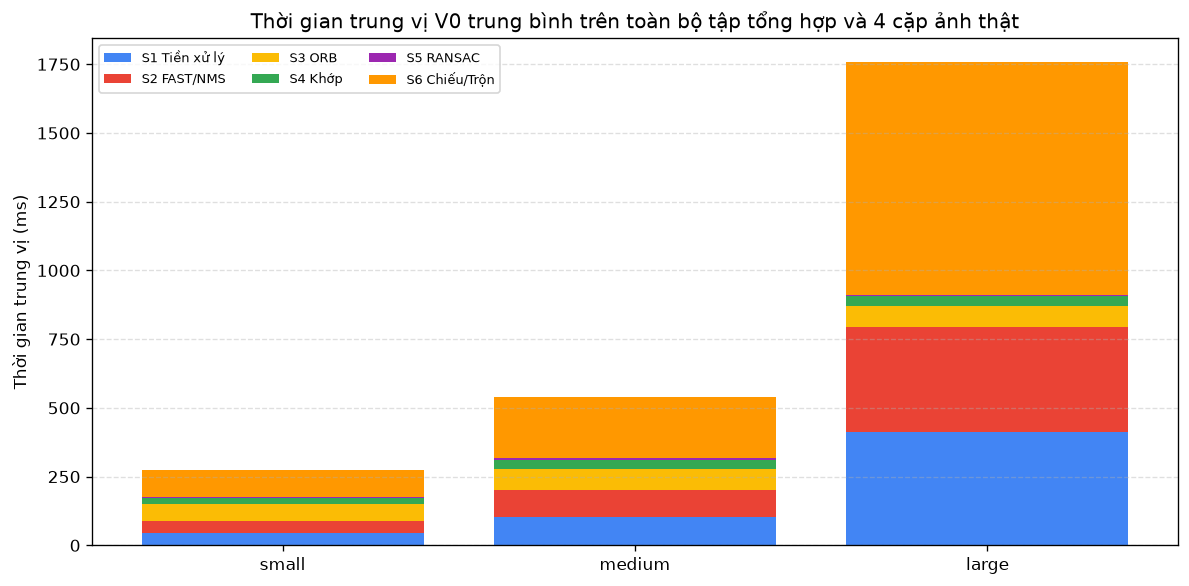

In [14]:
# 6.3 Phân tích giai đoạn thắt nút cổ chai (Hot stages) và Định luật Amdahl hữu hạn
import matplotlib.pyplot as plt
import numpy as np

stage_labels = ["S1 Tiền xử lý", "S2 FAST/NMS", "S3 ORB", "S4 Khớp", "S5 RANSAC", "S6 Chiếu/Trộn"]
stage_keys = [
    "stage1_preprocess", "stage2_fast_nms_topk", "stage3_orb_descriptor",
    "stage4_matching", "stage5_ransac", "stage6_warping_blending",
]
resolutions = ["small", "medium", "large"]
profile_rows = []
mean_by_resolution = {resolution: [] for resolution in resolutions}

for dataset_name in dataset_outputs:
    for resolution in resolutions:
        metrics = json.loads(
            (Path("output") / dataset_name / f"metrics_{resolution}.json").read_text()
        )
        times = np.array([metrics["timing_ms"][key]["median"] for key in stage_keys])
        mean_by_resolution[resolution].append(times)
        hot_index = int(np.argmax(times))
        profile_rows.append({
            "Tập dữ liệu": dataset_name,
            "Độ phân giải": resolution,
            "Giai đoạn thắt nút (Hot stage)": stage_labels[hot_index],
            "Tỷ lệ chiếm (%)": 100.0 * times[hot_index] / metrics["timing_ms"]["end_to_end"]["median"],
            "Amdahl p (S1+S2+S6)": metrics["amdahl_parallel_fraction"],
            "Giới hạn S_max hữu hạn": metrics["amdahl_smax"],
        })

print("Tập dữ liệu | Độ phân giải | Giai đoạn Hot | Chiếm (%) | Amdahl p | S_max hữu hạn")
print("-" * 90)
for row in profile_rows:
    print(
        f"{row['Tập dữ liệu']} | {row['Độ phân giải']} | {row['Giai đoạn thắt nút (Hot stage)']} | "
        f"{row['Tỷ lệ chiếm (%)']:.3f} | {row['Amdahl p (S1+S2+S6)']:.4f} | "
        f"{row['Giới hạn S_max hữu hạn']:.3f}"
    )

means = np.vstack([np.mean(mean_by_resolution[r], axis=0) for r in resolutions])
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(resolutions))
colors = ["#4285F4", "#EA4335", "#FBBC05", "#34A853", "#9C27B0", "#FF9800"]
for index, label in enumerate(stage_labels):
    ax.bar(resolutions, means[:, index], bottom=bottom, label=label, color=colors[index])
    bottom += means[:, index]
ax.set_title("Thời gian trung vị V0 trung bình trên toàn bộ tập tổng hợp và 4 cặp ảnh thật")
ax.set_ylabel("Thời gian trung vị (ms)")
ax.legend(ncol=3, fontsize=8)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("output/hot_stage_scaling.png", dpi=150)
plt.show()

for resolution, row in zip(resolutions, means):
    order = np.argsort(row)[::-1]
    print(
        f"{resolution}: Các giai đoạn chiếm ưu thế thời gian là "
        f"{stage_labels[order[0]]} ({row[order[0]]:.1f} ms), "
        f"{stage_labels[order[1]]} ({row[order[1]]:.1f} ms), và "
        f"{stage_labels[order[2]]} ({row[order[2]]:.1f} ms)."
    )
print(
    "Ưu tiên tăng tốc GPU là S1 + S2 + S6 vì chi phí của chúng tăng trực tiếp theo số lượng pixel "
    "và chiếm áp đảo trong profile đo đạc ở 1080p và 4K. S3-S5 và chi phí host được giữ tuần tự "
    "trong mô hình Amdahl bảo thủ này, vì vậy mọi giá trị S_max báo cáo đều là số hữu hạn."
)


In [15]:
# 6.4 Kiểm tra đối chiếu độc lập tính hợp lý của Homography với OpenCV
homography_report = Path("output/homography_reference.json")
run_checked([
    sys.executable, "scripts/validate_homography.py",
    "--json-out", str(homography_report),
])
reference = json.loads(homography_report.read_text())
print("site | độ phân giải | số match/inlier tham chiếu | Độ lệch lưới V0 so với tham chiếu (% đường chéo)")
for row in reference["comparisons"]:
    print(
        f"{row['site']} | {row['resolution']} | "
        f"{row['reference_matches']}/{row['reference_inliers']} | "
        f"{row['v0_reference_grid_disagreement_pct_diagonal']:.3f}"
    )
print("\nĐộ nhất quán của V0 qua các độ phân giải (Cross-resolution consistency):")
for row in reference["consistency"]:
    print(
        f"{row['site']} | {row['max_cross_resolution_grid_disagreement_pct_diagonal']:.3f}% đường chéo"
    )
print(
    "Diễn giải: Ảnh thật không có ma trận Ground-truth H. Do đó mô hình OpenCV SIFT + "
    "findHomography là một mốc đối chiếu tính hợp lý độc lập chứ không phải chân lý tuyệt đối. "
    "Độ lệch xuyên độ phân giải được đo sau khi chuẩn hóa hệ tọa độ; "
    "độ lệch lớn hơn ở các cảnh ít vân bề mặt cần được phân tích cùng với số lượng inlier "
    "và độ tự nhất quán xuyên độ phân giải của chính V0."
)


site	resolution	ref matches/inliers	V0-vs-ref grid disagreement (% diagonal)
site1	small	377/202	1.140
site1	medium	666/296	0.235
site1	large	661/257	1.101
site2	small	201/168	0.455
site2	medium	349/243	0.702
site2	large	231/90	3.403
site3	small	568/517	1.376
site3	medium	556/475	3.173
site3	large	406/312	1.224
challenging	small	465/428	0.380
challenging	medium	578/480	0.465
challenging	large	524/363	0.604

Cross-resolution V0 consistency (normalized coordinates):
site1: 1.331% diagonal
site2: 0.576% diagonal
site3: 1.935% diagonal
challenging: 0.503% diagonal
[OK] Wrote output\homography_reference.json
site | độ phân giải | số match/inlier tham chiếu | Độ lệch lưới V0 so với tham chiếu (% đường chéo)
site1 | small | 377/202 | 1.140
site1 | medium | 666/296 | 0.235
site1 | large | 661/257 | 1.101
site2 | small | 201/168 | 0.455
site2 | medium | 349/243 | 0.702
site2 | large | 231/90 | 3.403
site3 | small | 568/517 | 1.376
site3 | medium | 556/475 | 3.173
site3 | large | 406/312 | 1.224

---
## 7. BỘ SƯU TẬP ẢNH TOÀN CẢNH KẾT QUẢ (VISUAL GALLERY OF STITCHED PANORAMAS)


<notebook-cell-23>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


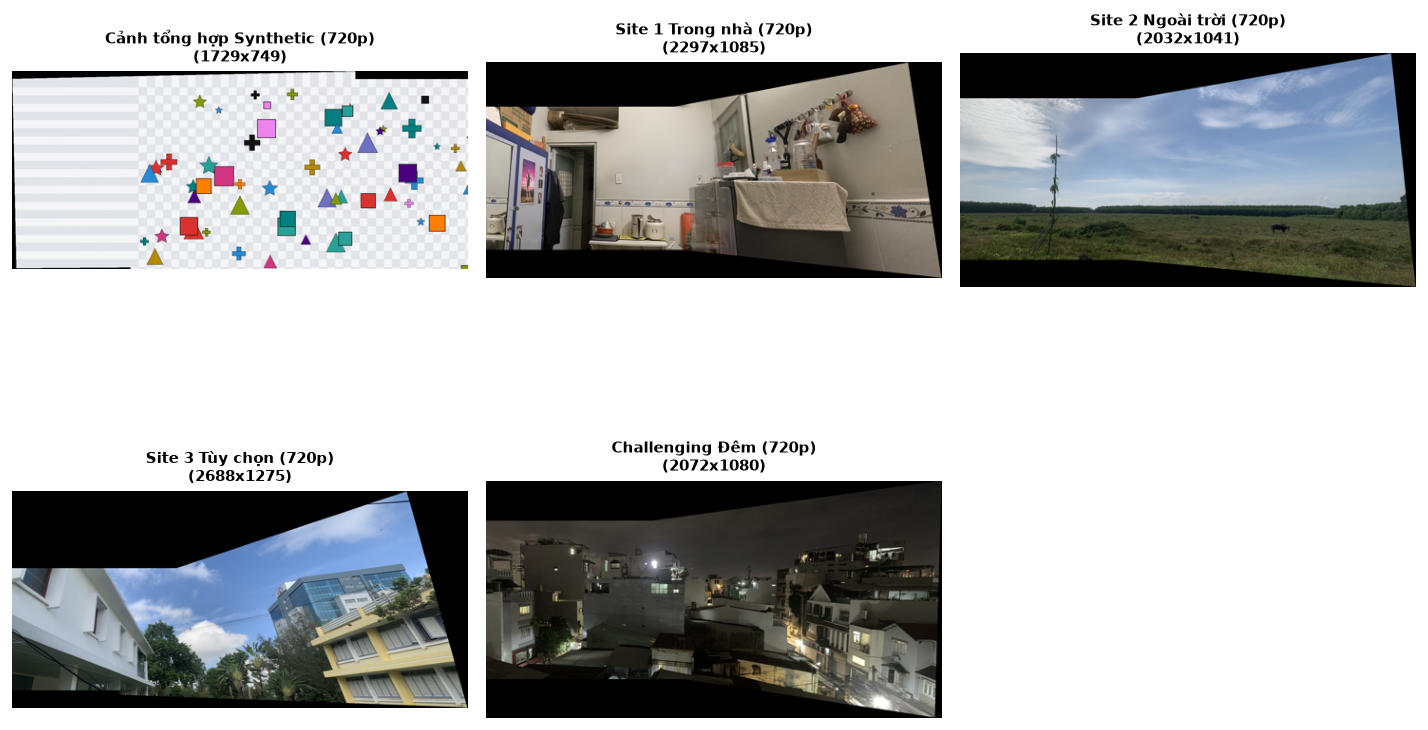

In [16]:
# 7.1 Hiển thị bộ sưu tập ảnh panorama kết quả đã ghép
import os
import matplotlib.pyplot as plt
from PIL import Image

panoramas = [
    ("Cảnh tổng hợp Synthetic (720p)", "output/synthetic/pano_small.jpg"),
    ("Site 1 Trong nhà (720p)", "output/site1/pano_small.jpg"),
    ("Site 2 Ngoài trời (720p)", "output/site2/pano_small.jpg"),
    ("Site 3 Tùy chọn (720p)", "output/site3/pano_small.jpg"),
    ("Challenging Đêm (720p)", "output/challenging/pano_small.jpg"),
]

plt.figure(figsize=(12, 8), dpi=75)
idx = 1
for title, p in panoramas:
    if os.path.isfile(p):
        img = Image.open(p)
        preview = img.copy()
        preview.thumbnail((480, 270))
        plt.subplot(2, 3, idx)
        plt.imshow(preview)
        plt.title(f"{title}\n({img.width}x{img.height})", fontsize=9, fontweight='bold')
        plt.axis('off')
        idx += 1

plt.tight_layout()
plt.show()


---
## 8. KẾ HOẠCH TRIỂN KHAI GPU (PHASES C, D, E) (GPU IMPLEMENTATION PLAN)

### 8.1 Lựa chọn dựa trên phân tích đo đạc (Profiling evidence)
Dựa trên số liệu đo đạc thực tế tại Cell 6.3: **S1, S2 và S6 là các mục tiêu tối ưu hóa đầu tiên** vì thời gian thực thi của chúng tăng theo kích thước ảnh và chiếm trên 90% tổng thời gian ở 1080p và 4K.  
Phiên bản V1 sẽ chuyển toàn bộ cả 6 giai đoạn lên GPU để dữ liệu trung gian luôn thường trú trên bộ nhớ thiết bị; mô hình Amdahl bảo thủ tập trung tăng tốc S1/S2/S6 và giữ S3-S5 cùng chi phí truyền nhận ở dạng tuần tự.

### 8.2 Bảng phân bố luồng V1 (V1 Thread Mapping)

| Giai đoạn | Cơ chế ánh xạ luồng CUDA | Rủi ro tính đúng đắn và giải pháp khắc phục |
|---|---|---|
| **S1 (Mức xám + Lọc mờ)** | Khối 2D $16\times 16$, 1 thread tính 1 pixel đầu ra | Lỗi vùng đệm halo/biên; kiểm tra đối chiếu từng chính sách biên clamp với V0 |
| **S2 (FAST + NMS + Top-K)** | Detector/NMS dạng 2D, thu gọn bounded compaction, khóa sắp xếp tất định | Tràn bộ đệm ứng viên và thứ tự atomic không tất định; cấp phát đúng dung lượng và tie-break ổn định |
| **S3 (Mô tả ORB)** | 1 thread xử lý 1 keypoint, bảng mẫu lưu trong `__constant__` memory | Vùng patch xoay vượt ngoài biên ảnh; tái sử dụng điều kiện biên an toàn của V0 |
| **S4 (Khớp đặc trưng)** | Phân khối tile 2D descriptor, chỉ thị phần cứng popcount, reduction tìm 2 điểm gần nhất | Sai lệch điểm nhì hoặc xử lý bằng điểm; kiểm thử hồi quy đối chiếu chính xác với matches của V0 |
| **S5 (RANSAC DLT)** | 1 thread hoặc warp xử lý 1 giả thuyết, seed LCG/ID giả thuyết tất định | Mẫu suy biến và phép thu gọn reduction không tất định; kiểm tra tính hữu hạn finite và tie-break tất định |
| **S6 (Chiếu & Trộn)** | Lưới 2D canvas, ánh xạ tọa độ ngược, lấy mẫu texture/bilinear | Canvas/alpha không hợp lệ và trôi dạt nội suy; xác thực biên trên host và kiểm tra dung sai pixel |

### 8.3 Các ý tưởng tối ưu hóa ứng viên (Một ý tưởng cốt lõi cho mỗi phiên bản)

1. **Phân khối bộ nhớ chia sẻ (Shared-Memory Tiling) cho S1 blur:** Tái sử dụng vùng lân cận $5\times 5$. Rủi ro: lưu lượng truyền vùng đệm halo, xung đột bank bộ nhớ và giảm occupancy có thể triệt tiêu hiệu năng.
2. **Thu gọn 2-pass compaction kèm sắp xếp GPU tất định cho S2:** Loại bỏ bước gom ứng viên tuần tự trên CPU. Rủi ro: tốn thêm bộ nhớ tạm và chi phí sắp xếp tăng ở ảnh nhỏ 720p.
3. **Lấy mẫu Texture-object phần cứng cho S6:** Tận dụng bộ đệm đọc 2D cache và nội suy phần cứng tích hợp của GPU. Rủi ro: sự khác biệt về làm tròn tọa độ so với CPU có thể vượt ngưỡng dung sai ảnh panorama.

Quyết định chọn tối ưu V2 sẽ dựa trên bằng chứng đo đạc Nsight Compute sau khi hoàn thành V1; V3 chỉ được lựa chọn sau khi profile lại V2. Chi phí truyền dữ liệu H2D/D2H, thiết lập, và thời gian kernel luôn được đo tách biệt để không che giấu chi phí giao tiếp.


---
## 9. MÃ NGUỒN BÊN THỨ BA, TÀI LIỆU THAM KHẢO & TUYÊN BỐ AI (THIRD-PARTY SOURCES, REFERENCES & AI DISCLOSURE)

- Bảng mẫu tọa độ OpenCV `bit_pattern_31_`, giấy phép BSD-3-Clause:  
  https://github.com/opencv/opencv/blob/4.x/modules/features2d/src/orb.cpp
- Thư viện đọc/ghi ảnh stb_image và stb_image_write, Public Domain / MIT:  
  https://github.com/nothings/stb
- Rosten & Drummond, Thuật toán phát hiện FAST, ECCV 2006:  
  https://doi.org/10.1007/11744023_34
- Rublee et al., Thuật toán mô tả đặc trưng ORB, ICCV 2011:  
  https://doi.org/10.1109/ICCV.2011.6126544
- Lowe, Phương pháp kiểm định tỷ số so khớp (Ratio test), IJCV 2004:  
  https://doi.org/10.1023/B:VISI.0000029664.99615.94
- Fischler & Bolles, Thuật toán RANSAC, CACM 1981:  
  https://doi.org/10.1145/358669.358692
- Hartley & Zisserman, *Multiple View Geometry in Computer Vision*, Tái bản lần 2, NXB Đại học Cambridge, 2004.

Mã nguồn/dữ liệu sao chép từ bên ngoài được giới hạn ở bảng tọa độ ORB của OpenCV và hai file tiêu đề nguyên bản của stb; chi tiết giấy phép được lưu tại `THIRD_PARTY_NOTICES.md`.  
Trí tuệ nhân tạo (Generative AI) được sử dụng để hỗ trợ rà soát mã nguồn, gợi ý danh mục kiểm tra kiểm thử và hiệu đính văn phong tài liệu. Các thành viên trong nhóm trực tiếp kiểm tra từng thay đổi, tự chạy kiểm thử/benchmark và hoàn toàn chịu trách nhiệm cho mọi kết quả nộp bài cũng như phần thuyết minh vấn đáp.


---
## 10. KIỂM TRA ĐÓNG GÓI BÀI NỘP (SUBMISSION PACKAGE PREFLIGHT)
Cell dưới đây kiểm tra tính hợp lệ của nội dung notebook, các tệp mã nguồn bắt buộc, tính toàn vẹn của tệp nén và quy cách đặt tên gói nộp bài. Gói nén cuối cùng được tái tạo lại sau khi toàn bộ notebook đã được lưu đầy đủ kết quả thực thi.


In [17]:
# 10.1 Đóng gói và xác thực tệp nộp bài giữa kỳ
run_checked([
    sys.executable, "scripts/package_midterm.py", "--group", "Group19",
    "--allow-unexecuted-notebook",
])


=== PACKAGING MIDTERM SUBMISSION: Group19_Midterm.zip ===
  + Added: Group19_Midterm.ipynb
  + Added: Makefile
  + Added: README.md
  + Added: requirements.txt
  + Added: project_plan_v4.md
  + Added: THIRD_PARTY_NOTICES.md
  + Added: src/common.h
  + Added: src/cuda_utils.cuh
  + Added: src/versions.h
  + Added: src/main.cu
  + Added: src/stb_image.h
  + Added: src/stb_image_write.h
  + Added: src/stb_impl.h
  + Added: src/stb_impl.cpp
  + Added: src/v0_sequential.h
  + Added: src/v0_sequential.cpp
  + Added: scripts/preprocess_dataset.py
  + Added: scripts/generate_synthetic_test.py
  + Added: scripts/orb_pattern_data.py
  + Added: scripts/validate_metrics.py
  + Added: scripts/validate_homography.py
  + Added: scripts/build_midterm_notebook.py
  + Added: scripts/execute_notebook.py
  + Added: scripts/package_midterm.py
  + Added: tests/test_cpu.cpp
  + Added: tests/test_scripts.py
  + Added: dataset/manifest.json
  + Added: dataset/synthetic/ground_truth.json

=== PACKAGE VERIFICATI